# ¿Quién abandona el banco y a quién retener primero?

Semana 11 | Redes neuronales en Keras | Mismo dataset: 10,000 clientes de un banco en Francia, Alemania y España

**El problema.** Un banco con 10,000 clientes en Francia, Alemania y España perdió al 20% de ellos. El equipo de retención no puede llamar a todos, así que necesita saber a quién contactar primero.

**De dónde venimos.**
- El **árbol de decisión** fue el mejor clasificador de la semana 8 (AUC de 0.840).
- En la semana 10, UMAP + DBSCAN mostró que el abandono depende mucho del **número de productos**, una relación que no es una recta.

**Pregunta de esta semana:** ¿una red neuronal detecta mejor a los clientes que se van que un modelo más simple?

**Qué hace este notebook**

| Parte | Pregunta | Lo que usamos (visto en clase) |
|---|---|---|
| 1 · Datos | ¿Seguimos con la misma información? | `read_csv`, one-hot, `train_test_split` (entrenamiento, validación y prueba), `StandardScaler` |
| 2 · Penalización de clases | ¿Cómo evitar que la red diga siempre «se queda»? | `class_weight` |
| 3 · Calificación y línea base | ¿Contra qué comparamos? | Matriz de confusión, recall, precisión, F1, AUC, línea base «nadie abandona» |
| 4 · Modelos de referencia | ¿Qué tan bien lo hacen los modelos de la semana 8? | Regresión logística y árbol de decisión, con penalización |
| 5 · Una neurona | ¿Una neurona es una regresión logística? | `keras.Sequential`, `Dense`, sigmoide |
| 6 · La red (16, 8) | ¿Qué aprende una red con capas ocultas? | Capas ocultas, Adam, `binary_crossentropy`, `EarlyStopping` |
| 7 · Sobreajuste | ¿Qué pasa si la red es muy grande? | Curvas de error, `EarlyStopping`, `Dropout` |
| 8 · Tamaño de la red | ¿Más neuronas es mejor? | Comparación con validación |
| 9 · Comparación final | ¿La red supera a los modelos simples? | Las mismas métricas con los clientes de prueba |
| 10 a 13 · Para el banco | ¿A quién llamar y cuánto cuesta equivocarse? | Llamadas por cliente encontrado, perfiles de riesgo, presupuesto, costo de FN y FP |
| 14 · Conclusiones | ¿A quién retener primero? | Lo que aprendimos esta semana |

**Decisiones del equipo:**
- El desbalance (solo ~20% abandona) se maneja con **penalización de clases** (`class_weight`): fallar con un cliente que se va cuesta más que fallar con uno que se queda. No se usa SMOTE.
- El sobreajuste se controla con **EarlyStopping** y **Dropout(0.2)**, las dos técnicas vistas en clase.

## 1. Datos | Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)
import keras
from keras import layers

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)   # fija el azar de NumPy, Python y Keras: mismos resultados cada vez
plt.rcParams["figure.figsize"] = (7, 4)

I0000 00:00:1795056439.261145   20281 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795056440.426012   20281 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
try:
    from google.colab import files
    import os
    if not os.path.exists("Churn_Modelling.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("Churn_Modelling.csv")
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(df.shape)
print(f"Tasa de abandono: {df['Exited'].mean():.1%}")

# One-hot igual que en la semana 8: Geography y Gender pasan a columnas de 0 y 1
datos = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True, dtype=int)

(10000, 11)
Tasa de abandono: 20.4%


### 1.1 Tres grupos de clientes
- **Entrenamiento (68%):** la red aprende con ellos.
- **Validación (12%):** sirve para decidir cuándo parar (EarlyStopping) y para comparar tamaños de red.
- **Prueba (20%):** se usa **una sola vez**, al final, para la comparación honesta.

El primer corte es **el mismo de la semana 8** (`test_size=0.2`, `stratify=y`, semilla 42): los **mismos 2,000 clientes de prueba**. Lo nuevo es que el 80% restante se divide otra vez para tener validación. Las dos divisiones usan `stratify`, así los tres grupos conservan el ~20% de abandono.

In [3]:
X = datos.drop(columns="Exited")
y = datos["Exited"]

X_resto, X_test, y_resto, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)          # mismo corte que la semana 8
X_train, X_val, y_train, y_val = train_test_split(
    X_resto, y_resto, test_size=0.15, stratify=y_resto, random_state=SEMILLA)

for nombre, yy in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    print(f"{nombre:14s} {len(yy):5d} clientes · abandono = {yy.mean():.3f}")

Entrenamiento   6800 clientes · abandono = 0.204
Validación      1200 clientes · abandono = 0.203
Prueba          2000 clientes · abandono = 0.203


### 1.2 Estandarizar
Igual que en la semana 8: una red aprende mejor si todas las variables están en la misma escala (saldo en miles y edad en decenas confundirían los pasos del descenso por gradiente).
El escalador se ajusta **solo con entrenamiento** para no filtrar información de validación ni de prueba.

In [4]:
scaler = StandardScaler().fit(X_train)
X_train_esc = scaler.transform(X_train)
X_val_esc = scaler.transform(X_val)
X_test_esc = scaler.transform(X_test)
N_VARIABLES = X_train_esc.shape[1]
print("Variables de entrada:", N_VARIABLES, list(X.columns))

Variables de entrada: 11 ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


## 2 · Penalización de clases
**Pregunta:** ¿cómo evitar que la red diga siempre «se queda»?

Por cada cliente que abandona hay ~4 que se quedan. Si el error pesa igual para todos, a la red le conviene decir casi siempre «se queda».
Con `class_weight` el error de un cliente que abandona **cuenta más**: tanto como la proporción entre ambos grupos.

In [5]:
n_quedan = int((y_train == 0).sum())
n_van = int((y_train == 1).sum())
PESOS_CLASE = {0: 1.0, 1: n_quedan / n_van}
print(f"Se quedan: {n_quedan} · Abandonan: {n_van}")
print("Pesos de clase:", {k: round(v, 2) for k, v in PESOS_CLASE.items()})

Se quedan: 5414 · Abandonan: 1386
Pesos de clase: {0: 1.0, 1: 3.91}


## 3 · Cómo vamos a calificar a los modelos
Usamos las mismas métricas de la semana 8. Todo sale de la **matriz de confusión**:
- **VP:** se iba y lo detectamos · **FN:** se iba y no lo detectamos (cliente perdido)
- **FP:** lo marcamos y no se iba (llamada de más) · **VN:** se quedaba y no lo marcamos

- **Accuracy:** de todos, ¿cuántos acertó?
- **Recall:** de los que se fueron, ¿cuántos detectó? → **la más importante aquí**, porque el error más caro es el FN.
- **Precisión:** de los que marcó, ¿cuántos sí se fueron?
- **Especificidad:** de los que se quedaron, ¿cuántos reconoció?
- **F1:** equilibrio entre recall y precisión.
- **AUC:** qué tan bien ordena a los clientes de más a menos riesgo, sin depender del umbral (0.5 = azar, 1 = perfecto).

In [6]:
resultados = {}

def evaluar(nombre, prob, umbral=0.5):
    # Métricas de la semana 8 a partir de la probabilidad de abandono
    prob = np.asarray(prob).ravel()
    pred = (prob >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Precisión": precision_score(y_test, pred, zero_division=0),
        "Especificidad": vn / (vn + fp),
        "F1": f1_score(y_test, pred, zero_division=0),
        "AUC": roc_auc_score(y_test, prob) if len(np.unique(prob)) > 1 else 0.5,
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
    }
    return pd.Series(resultados[nombre]).round(3)

# Línea base: «nadie abandona» (probabilidad 0 para todos)
evaluar("Nadie abandona (línea base)", np.zeros(len(y_test)))

Accuracy            0.796
Recall              0.000
Precisión           0.000
Especificidad       1.000
F1                  0.000
AUC                 0.500
VP                  0.000
FP                  0.000
FN                407.000
VN               1593.000
dtype: float64

**Qué vemos:** igual que en la semana 8, la línea base acierta ~80% sin hacer nada, pero no detecta **ni un** cliente que se va (recall = 0). Por eso el accuracy engaña: comparamos con recall, precisión, F1 y AUC.

## 4 · Modelos de referencia (semana 8), también con penalización
**Pregunta:** ¿qué tan bien lo hacen los modelos simples en las mismas condiciones que la red?

Se reentrenan con los mismos clientes de entrenamiento. `class_weight="balanced"` es la misma penalización de la sección 2, calculada por scikit-learn.

**Diferencia con la semana 8:** allá el árbol tenía profundidad 6 y sin penalización. Aquí, con penalización y `min_samples_leaf=20`, usamos **profundidad 7**, que es la que mejor le va al árbol: así la red se compara contra **el árbol más fuerte**. (Con profundidad 6 el árbol queda un poco abajo: F1 de 0.56 y costo de 133,800 en la sección 13.)

In [7]:
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEMILLA)
logreg.fit(X_train_esc, y_train)

PROF_ARBOL = 7   # con penalización, la mejor profundidad para el árbol (la semana 8 usó 6 sin penalización)
arbol = DecisionTreeClassifier(max_depth=PROF_ARBOL, min_samples_leaf=20,
                               class_weight="balanced", random_state=SEMILLA)
arbol.fit(X_train, y_train)   # el árbol no necesita datos estandarizados
print("Modelos de referencia entrenados.")

Modelos de referencia entrenados.


## 5 · Una sola neurona en Keras = regresión logística
En clase vimos que **una neurona es una regresión logística**: multiplica cada dato por un peso, suma un sesgo y la sigmoide lo convierte en probabilidad.
**Pregunta:** ¿una neurona es lo mismo que una regresión logística? Aquí lo comprobamos: una red sin capas ocultas.

Parámetros: 11 pesos (uno por variable) + 1 sesgo = **12**.

In [8]:
neurona = keras.Sequential([
    keras.Input(shape=(N_VARIABLES,)),
    layers.Dense(1, activation="sigmoid"),
])
neurona.compile(optimizer="adam", loss="binary_crossentropy")
neurona.summary()

neurona.fit(X_train_esc, y_train, epochs=100, batch_size=32, class_weight=PESOS_CLASE,
            validation_data=(X_val_esc, y_val), verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                     restore_best_weights=True)])

pesos = pd.DataFrame({"Neurona (Keras)": neurona.layers[0].get_weights()[0].ravel(),
                      "Regresión logística": logreg.coef_[0]}, index=X.columns).round(2)
pesos

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12 (48.00 B)

 Trainable params: 12 (48.00 B)

 Non-trainable params: 0 (0.00 B)

,Neurona (Keras),Regresión logística
CreditScore,-0.05,-0.06
Age,0.78,0.79
Tenure,-0.04,-0.04
Balance,0.20,0.20
NumOfProducts,-0.04,-0.05
HasCrCard,-0.05,-0.04
IsActiveMember,-0.47,-0.47
EstimatedSalary,0.05,0.05
Geography_Germany,0.31,0.32
Geography_Spain,-0.01,-0.01


**Qué vemos:** los pesos de la neurona y los coeficientes de la regresión logística tienen **el mismo signo** y casi el mismo valor: **edad** (+0.78), **miembro activo** (−0.47), **Alemania** (+0.31) y **hombre** (−0.29) son los que más pesan, igual que en el mapa de calor de la semana 7.
Un peso positivo empuja hacia «abandona»; uno negativo, hacia «se queda». No son idénticos porque se ajustan con métodos distintos.

## 6 · La red: 16 y 8 neuronas
**Pregunta:** ¿qué aprende una red con capas ocultas?

Es el mismo tamaño que en el laboratorio de clase.
- **Capas ocultas:** 16 y 8 neuronas con activación **sigmoide**, la misma función de la neurona que vimos en clase.
- **Salida:** 1 neurona con **sigmoide**, que da la probabilidad de abandonar.
- **Optimizador Adam:** descenso por gradiente que ajusta solo el tamaño del paso.
- **Pérdida `binary_crossentropy`:** el error que castiga fallar con seguridad (log-loss).

Parámetros: (11×16 + 16) + (16×8 + 8) + (8×1 + 1) = 192 + 136 + 9 = **337**.

In [9]:
def crear_red(capas=(16, 8), dropout=0.0):
    """Red densa para clasificación binaria con las capas ocultas indicadas."""
    modelo = keras.Sequential([keras.Input(shape=(N_VARIABLES,))])
    for n in capas:
        modelo.add(layers.Dense(n, activation="sigmoid"))
        if dropout > 0:
            modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(1, activation="sigmoid"))
    modelo.compile(optimizer="adam", loss="binary_crossentropy")
    return modelo

def detener_a_tiempo():
    """Para cuando el error de validación lleva 15 épocas sin bajar y regresa a los mejores pesos."""
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

keras.utils.set_random_seed(SEMILLA)
red = crear_red((16, 8))
red.summary()

historia = red.fit(X_train_esc, y_train, epochs=300, batch_size=32, class_weight=PESOS_CLASE,
                   validation_data=(X_val_esc, y_val), callbacks=[detener_a_tiempo()], verbose=0)
print("Épocas ejecutadas:", len(historia.history["loss"]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Épocas ejecutadas: 124


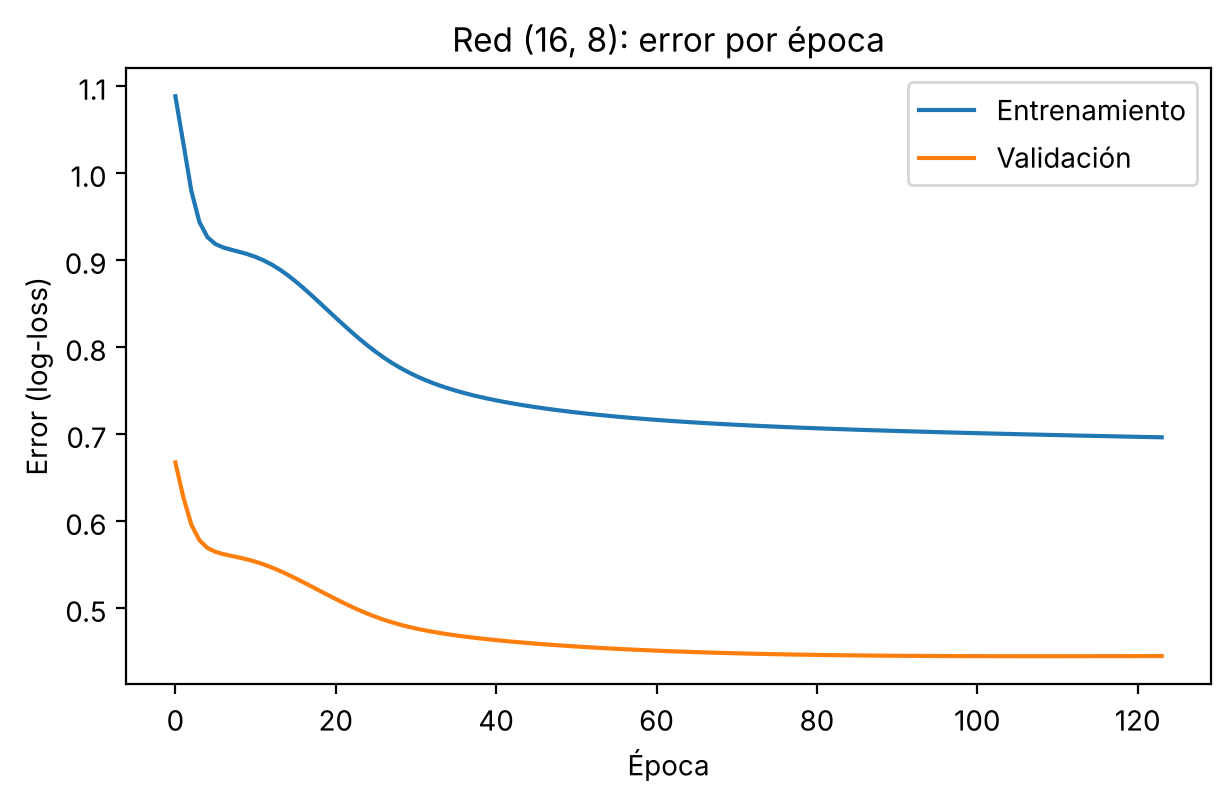

In [10]:
plt.plot(historia.history["loss"], label="Entrenamiento")
plt.plot(historia.history["val_loss"], label="Validación")
plt.title("Red (16, 8): error por época")
plt.xlabel("Época"); plt.ylabel("Error (log-loss)"); plt.legend(); plt.show()

**Qué vemos:** las dos curvas bajan juntas al principio. Cuando la de validación deja de bajar, la red empieza a memorizar; ahí EarlyStopping detiene el entrenamiento y regresa a los pesos de la mejor época.

**Pregunta probable: ¿por qué el error de entrenamiento queda arriba del de validación?** Por la penalización de clases: en entrenamiento, cada error con un cliente que abandona cuenta ~3.9 veces; en validación todos cuentan igual. Las dos curvas no están en la misma escala, así que lo que se compara es su **tendencia**, no su altura. (Con Dropout pasa algo parecido: apaga neuronas solo al entrenar.)

## 7 · Sobreajuste: red grande sin freno contra red con freno
Como en clase: una red grande (256 y 256 neuronas) entrenada muchas épocas **memoriza** el entrenamiento. Con sigmoide aprende más despacio, por eso se entrena 400 épocas para que el sobreajuste se vea.
Se compara contra la misma red con **EarlyStopping** y **Dropout(0.2)** (en cada ajuste apaga al azar el 20 % de las neuronas, para que ninguna cargue con todo).

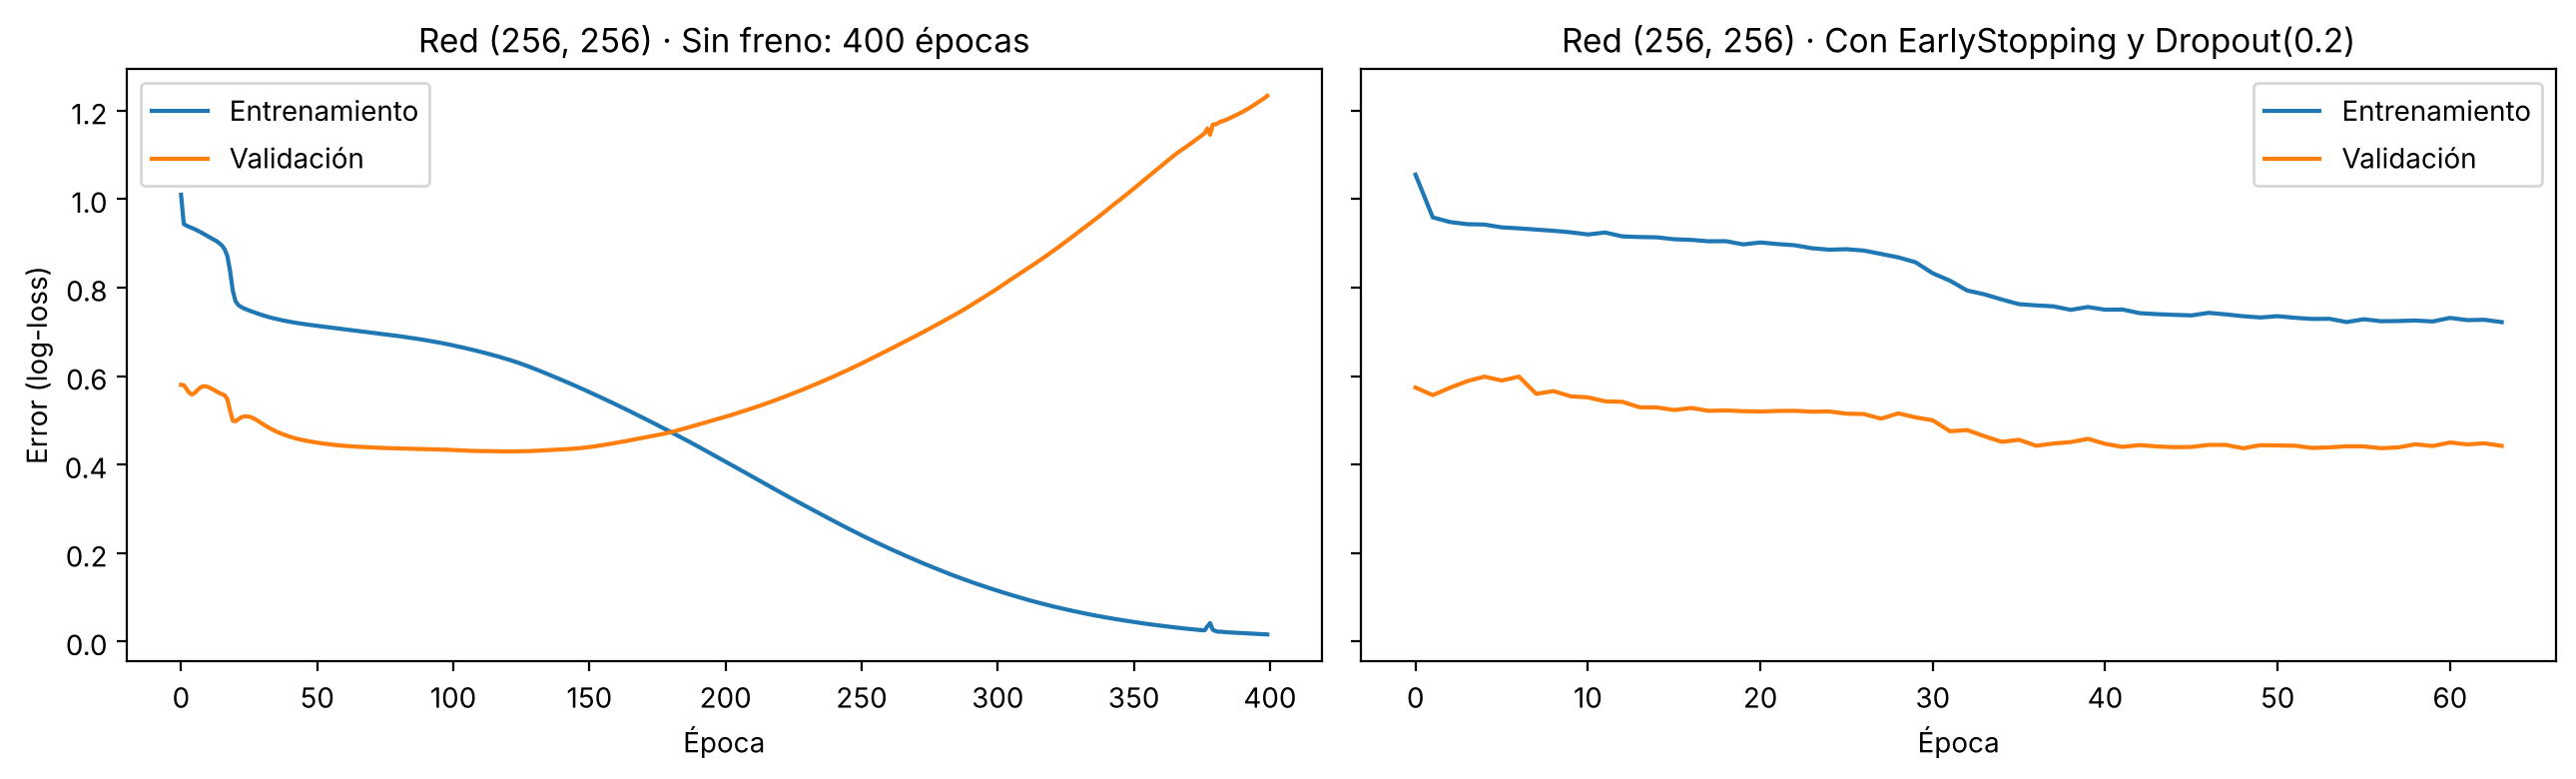

Parámetros de la red grande: 69121 · de la red (16, 8): 337


In [11]:
keras.utils.set_random_seed(SEMILLA)
grande = crear_red((256, 256))
h_grande = grande.fit(X_train_esc, y_train, epochs=400, batch_size=32, class_weight=PESOS_CLASE,
                      validation_data=(X_val_esc, y_val), verbose=0)

keras.utils.set_random_seed(SEMILLA)
grande_freno = crear_red((256, 256), dropout=0.2)
h_freno = grande_freno.fit(X_train_esc, y_train, epochs=300, batch_size=32, class_weight=PESOS_CLASE,
                           validation_data=(X_val_esc, y_val), callbacks=[detener_a_tiempo()], verbose=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, h, titulo in [(a1, h_grande, "Sin freno: 400 épocas"),
                      (a2, h_freno, "Con EarlyStopping y Dropout(0.2)")]:
    ax.plot(h.history["loss"], label="Entrenamiento")
    ax.plot(h.history["val_loss"], label="Validación")
    ax.set_title(f"Red (256, 256) · {titulo}"); ax.set_xlabel("Época"); ax.legend()
a1.set_ylabel("Error (log-loss)")
plt.tight_layout(); plt.show()
print("Parámetros de la red grande:", grande.count_params(), "· de la red (16, 8):", red.count_params())

**Qué vemos:** sin freno, el error de entrenamiento sigue bajando pero el de validación **sube**: eso es memorizar, no aprender.
Con freno, el entrenamiento se detiene cerca del mejor punto de validación.

## 8 · ¿Qué tamaño de red conviene?
Tres tamaños, todos con EarlyStopping y penalización de clases. Se comparan con los clientes de **validación** (la prueba se guarda para el final).

In [12]:
tamanos = {"(8)": (8,), "(16, 8)": (16, 8), "(64, 32)": (64, 32)}
filas = []
for nombre, capas in tamanos.items():
    keras.utils.set_random_seed(SEMILLA)
    m = crear_red(capas)
    m.fit(X_train_esc, y_train, epochs=300, batch_size=32, class_weight=PESOS_CLASE,
          validation_data=(X_val_esc, y_val), callbacks=[detener_a_tiempo()], verbose=0)
    prob = m.predict(X_val_esc, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    filas.append({"red": nombre, "parámetros": m.count_params(),
                  "recall": recall_score(y_val, pred), "precisión": precision_score(y_val, pred),
                  "F1": f1_score(y_val, pred), "AUC": roc_auc_score(y_val, prob)})
pd.DataFrame(filas).set_index("red").round(3)

,parámetros,recall,precisión,F1,AUC
red,,,,,
(8),105,0.734,0.474,0.576,0.855
"(16, 8)",337,0.734,0.486,0.585,0.853
"(64, 32)",2881,0.717,0.504,0.592,0.851


**Qué vemos:** los tres tamaños quedan casi iguales (AUC de 0.85 a 0.86), aunque la red (64, 32) tiene 8 veces más parámetros que la (16, 8). Si la red más grande no mejora claramente, conviene la más pequeña: entrena más rápido y sobreajusta menos. Nos quedamos con (16, 8).

## 9 · Comparación final con los clientes de prueba
Es la única vez que se usan los clientes de prueba. Todos los modelos tienen penalización de clases y umbral 0.5.

In [13]:
evaluar("Regresión logística (balanced)", logreg.predict_proba(X_test_esc)[:, 1])
evaluar(f"Árbol (prof={PROF_ARBOL}, balanced)", arbol.predict_proba(X_test)[:, 1])
evaluar("Neurona sola (Keras)", neurona.predict(X_test_esc, verbose=0).ravel())
evaluar("Red (16, 8) (Keras)", red.predict(X_test_esc, verbose=0).ravel())

tabla = pd.DataFrame(resultados).T
tabla[["VP", "FP", "FN", "VN"]] = tabla[["VP", "FP", "FN", "VN"]].astype(int)
tabla.round(3)

,Accuracy,Recall,Precisión,Especificidad,F1,AUC,VP,FP,FN,VN
Nadie abandona (línea base),0.796,0.000,0.000,1.000,0.000,0.500,0,0,407,1593
Regresión logística (balanced),0.710,0.705,0.384,0.711,0.497,0.778,287,461,120,1132
"Árbol (prof=7, balanced)",0.768,0.786,0.460,0.764,0.580,0.840,320,376,87,1217
Neurona sola (Keras),0.710,0.710,0.385,0.711,0.500,0.778,289,461,118,1132
"Red (16, 8) (Keras)",0.787,0.776,0.485,0.790,0.597,0.866,316,335,91,1258


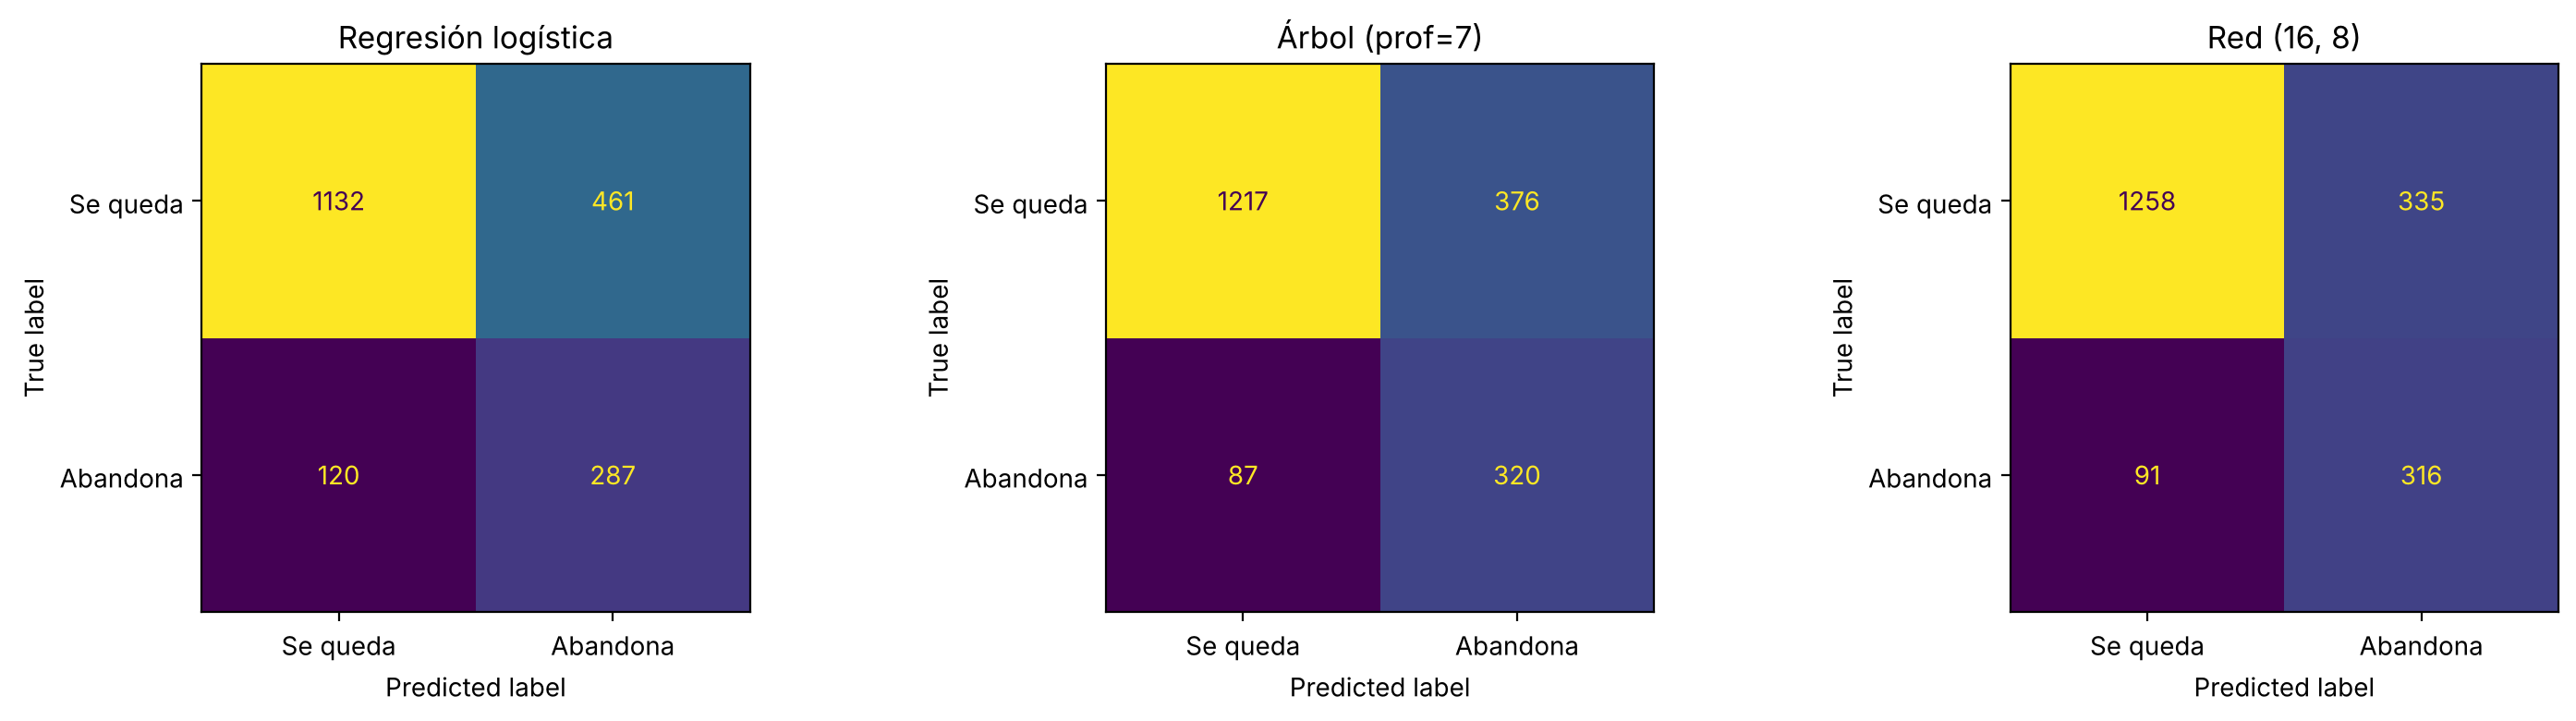

In [14]:
modelos_finales = {
    "Regresión logística": logreg.predict_proba(X_test_esc)[:, 1],
    f"Árbol (prof={PROF_ARBOL})": arbol.predict_proba(X_test)[:, 1],
    "Red (16, 8)": red.predict(X_test_esc, verbose=0).ravel(),
}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, prob) in zip(ejes, modelos_finales.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (prob >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["Se queda", "Abandona"])
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

## 10 · Lectura para el banco
La misma comparación, en el idioma de quien decide: **a cuántos clientes habría que llamar** y **a cuántos de los que se iban encontraríamos**.

In [15]:
total_van = int(y_test.sum())
lectura = pd.DataFrame({
    "Clientes a llamar": tabla["VP"] + tabla["FP"],
    "% de la cartera": ((tabla["VP"] + tabla["FP"]) / len(y_test) * 100).round(1),
    f"Encontrados (de {total_van} que se van)": tabla["VP"],
    "% encontrados": (tabla["VP"] / total_van * 100).round(1),
    "Llamadas de más": tabla["FP"],
    "Clientes perdidos sin aviso": tabla["FN"],
})
lectura["Llamadas por cada cliente encontrado"] = (
    lectura["Clientes a llamar"] / lectura[f"Encontrados (de {total_van} que se van)"].replace(0, np.nan)).round(2)
lectura

,Clientes a llamar,% de la cartera,Encontrados (de 407 que se van),% encontrados,Llamadas de más,Clientes perdidos sin aviso,Llamadas por cada cliente encontrado
Nadie abandona (línea base),0,0.0,0,0.0,0,407,NaN
Regresión logística (balanced),748,37.4,287,70.5,461,120,2.61
"Árbol (prof=7, balanced)",696,34.8,320,78.6,376,87,2.17
Neurona sola (Keras),750,37.5,289,71.0,461,118,2.60
"Red (16, 8) (Keras)",651,32.6,316,77.6,335,91,2.06


**Qué vemos:** «llamadas por cada cliente encontrado» dice cuántas llamadas hace el equipo de retención para dar con un cliente que sí se iba. Llamar a todos al azar costaría ~4.9 llamadas por cliente encontrado (porque solo ~20 % se va); un buen modelo baja ese número. La red baja a **2.06** y el árbol a 2.17.

## 11 · ¿Qué perfiles marca la red como riesgosos?
Se compara, por grupo de clientes de prueba, el **abandono real** contra la **probabilidad promedio que da la red**.
Si se parecen, la red aprendió los mismos patrones que encontró las semanas anteriores (mapa de calor de la semana 7 y segmentos de la semana 10).

In [16]:
prob_red = red.predict(X_test_esc, verbose=0).ravel()
perfil = pd.DataFrame({
    "País": np.select([X_test["Geography_Germany"] == 1, X_test["Geography_Spain"] == 1],
                      ["Alemania", "España"], default="Francia"),
    "Miembro activo": X_test["IsActiveMember"].map({1: "Sí", 0: "No"}),
    "Productos": X_test["NumOfProducts"].astype(str),
    "Edad": pd.cut(X_test["Age"], bins=[17, 30, 40, 50, 60, 100],
                   labels=["18-30", "31-40", "41-50", "51-60", "61+"]).astype(str),
    "real": y_test.values,
    "prob_red": prob_red,
})

def riesgo_por(columna):
    """Abandono real y probabilidad promedio de la red para cada valor de la columna."""
    return (perfil.groupby(columna)
            .agg(clientes=("real", "size"), abandono_real=("real", "mean"), prob_red=("prob_red", "mean"))
            .round(3))

for col in ["País", "Miembro activo", "Productos", "Edad"]:
    print(f"--- {col} ---")
    print(riesgo_por(col), "\n")

--- País ---
          clientes  abandono_real  prob_red
País                                       
Alemania       504          0.300     0.529
España         475          0.171     0.338
Francia       1021          0.171     0.330 

--- Miembro activo ---
                clientes  abandono_real  prob_red
Miembro activo                                   
No                   968          0.275     0.466
Sí                  1032          0.137     0.304 

--- Productos ---
           clientes  abandono_real  prob_red
Productos                                   
1              1013          0.267     0.502
2               918          0.084     0.208
3                59          0.847     0.935
4                10          1.000     0.991 

--- Edad ---
       clientes  abandono_real  prob_red
Edad                                    
18-30       399          0.063     0.200
31-40       868          0.114     0.298
41-50       492          0.350     0.581
51-60       152          0.586  

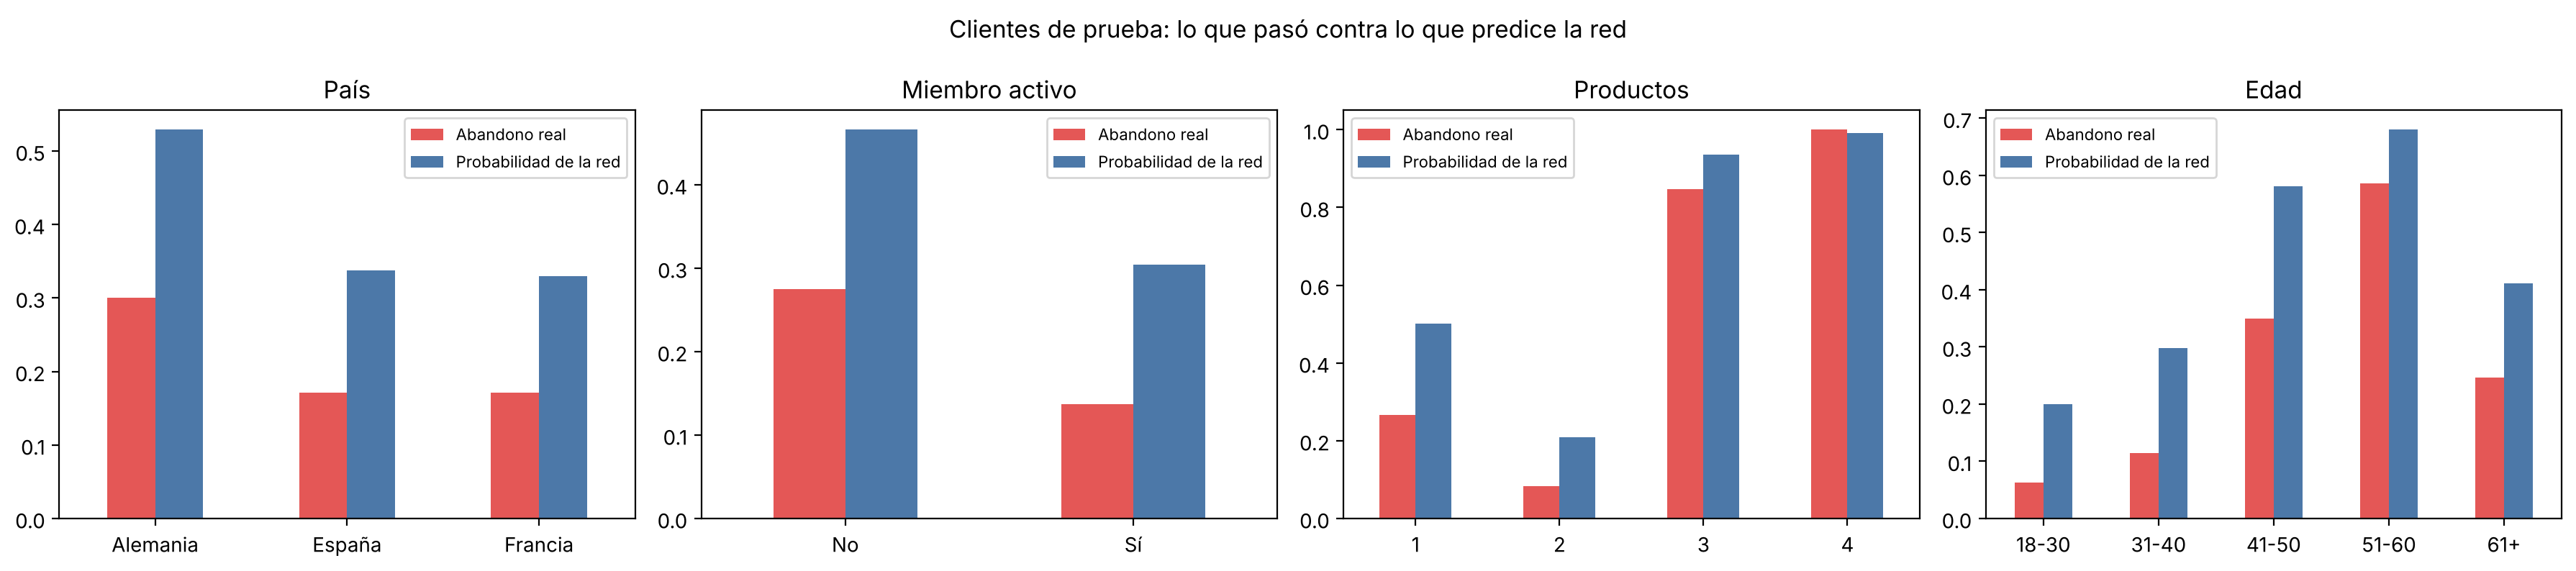

In [17]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(ejes, ["País", "Miembro activo", "Productos", "Edad"]):
    riesgo_por(col)[["abandono_real", "prob_red"]].plot(kind="bar", ax=ax, color=["#E45756", "#4C78A8"])
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.legend(["Abandono real", "Probabilidad de la red"], fontsize=8)
plt.suptitle("Clientes de prueba: lo que pasó contra lo que predice la red")
plt.tight_layout(); plt.show()

**Qué vemos:** la probabilidad de la red sale más alta que el abandono real en todos los grupos porque se entrenó con penalización de clases (exagera a propósito el riesgo para no perder clientes). Lo que importa es que **el orden** de los grupos coincida: Alemania arriba de Francia y España, inactivos arriba de activos, 3 y 4 productos muy arriba, y el riesgo subiendo con la edad hasta los 51-60 años para bajar después de los 61.

## 12 · ¿Y si solo hay presupuesto para pocas llamadas?
El banco no siempre puede llamar a todos los que marca el modelo. Se ordenan los clientes de prueba **de mayor a menor probabilidad** y se ve cuántos de los que se iban hay en los primeros.

In [18]:
orden = perfil.sort_values("prob_red", ascending=False).reset_index(drop=True)
filas = []
for pct in [5, 10, 20, 30, 50]:
    n = int(len(orden) * pct / 100)
    encontrados = int(orden["real"].iloc[:n].sum())
    filas.append({"Llamar al top %": pct, "Clientes llamados": n,
                  "Se iban de verdad": encontrados,
                  "% de los llamados que se iban": round(encontrados / n * 100, 1),
                  f"% de los {total_van} que se van": round(encontrados / total_van * 100, 1)})
presupuesto = pd.DataFrame(filas).set_index("Llamar al top %")
presupuesto

,Clientes llamados,Se iban de verdad,% de los llamados que se iban,% de los 407 que se van
Llamar al top %,,,,
5,100,95,95.0,23.3
10,200,167,83.5,41.0
20,400,256,64.0,62.9
30,600,306,51.0,75.2
50,1000,363,36.3,89.2


**Qué vemos:** si se llama al azar, solo ~20 % de los llamados se iba. Con la lista ordenada por la red, en el top 10% el **84%** de los llamados sí se iba. Esta tabla responde «¿cuántas llamadas al día vale la pena hacer?».

## 13 · ¿Cuánto cuesta equivocarse?
La rúbrica pide justificar las métricas por el costo de cada error. **Los costos de abajo son supuestos del equipo: cámbienlos y citen de dónde salen.**
- **FN (cliente que se va sin que lo detectemos):** se pierde el margen que dejaba ese cliente.
- **FP (llamada a quien no se iba):** se gasta en la llamada o la oferta de retención.

In [19]:
COSTO_FN = 1000   # SUPUESTO: valor de perder un cliente (cámbienlo)
COSTO_FP = 100    # SUPUESTO: costo de una llamada u oferta de retención (cámbienlo)

costos = tabla.assign(costo_total=tabla["FN"] * COSTO_FN + tabla["FP"] * COSTO_FP)
costos[["VP", "FN", "FP", "costo_total"]].sort_values("costo_total")

,VP,FN,FP,costo_total
"Red (16, 8) (Keras)",316,91,335,124500
"Árbol (prof=7, balanced)",320,87,376,124600
Neurona sola (Keras),289,118,461,164100
Regresión logística (balanced),287,120,461,166100
Nadie abandona (línea base),0,407,0,407000


**Qué vemos:** el mejor modelo para el banco es el de **menor costo total**, no necesariamente el de mayor exactitud.
La red (124,500) y el árbol (124,600) cuestan prácticamente lo mismo; la regresión logística y la neurona sola cuestan unos 40,000 más. Cuando dos modelos cuestan casi igual, conviene el más simple: se explica mejor a quien decide.

### 13.1 Guardar la red y las probabilidades
La red queda guardada para usarla con clientes nuevos, y las probabilidades pueden alimentar el tablero de Power BI.

In [20]:
red.save("modelo_red_16_8.keras")

salida = X_test.copy()
salida["Exited_real"] = y_test.values
salida["prob_abandono"] = red.predict(X_test_esc, verbose=0).ravel().round(4)
salida.sort_values("prob_abandono", ascending=False).to_csv("probabilidades_prueba.csv", index_label="fila_original")
print("Guardados: modelo_red_16_8.keras y probabilidades_prueba.csv")
salida.sort_values("prob_abandono", ascending=False).head()

Guardados: modelo_red_16_8.keras y probabilidades_prueba.csv


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male,Exited_real,prob_abandono
9540,727,46,3,115248.11,4,1,0,130752.01,1,0,1,1,0.9946
70,738,58,2,133745.44,4,1,0,28373.86,1,0,1,1,0.9946
5386,642,48,9,118317.27,4,0,0,78702.98,0,0,1,1,0.9945
5010,575,49,7,121205.15,4,1,1,168080.53,1,0,1,1,0.9941
2541,611,61,3,131583.59,4,0,1,66238.23,0,0,0,1,0.9935


## 14 · Conclusiones para el banco

**Respuesta a la pregunta de esta semana: ¿la red supera a los modelos simples?**
- **A la regresión logística, sí, claramente:** F1 de 0.60 contra 0.50, y detecta a 316 de 407 clientes que se van contra 287. Sus capas ocultas captan relaciones que no son rectas, como la del número de productos que vimos en la semana 10.
- **Al árbol, no: quedan prácticamente empatados.** La red tiene mejor F1 (0.60 contra 0.58), mejor AUC (0.87 contra 0.84) y menos llamadas de más (335 contra 376), pero el árbol encuentra un poco más de los que se van (320 contra 316). El costo total es casi igual (124,500 contra 124,600).
- **Una neurona sola es una regresión logística:** mismos pesos y mismos resultados.
- **El sobreajuste se ve y se controla:** la red de 256 y 256 neuronas sin freno memorizó (su error de validación subió de 0.43 a 1.23); con EarlyStopping y Dropout(0.2) se mantuvo estable cerca de 0.44. La red final de 16 y 8 neuronas se detuvo sola en la época 124.

**¿Se justifica una red con 10,000 clientes y 11 variables?** Solo en parte. Como vimos en clase, en datos de tabla una red no siempre gana: aquí empata con un árbol, que es más fácil de explicar. La red conviene si el banco prioriza **ordenar bien el riesgo** (mejor AUC, menos llamadas de más); si necesita **explicar cada decisión**, el árbol es la opción más prudente.

**¿A quién retener primero?**
1. Ordenar cada mes a los clientes por su riesgo: llamando a un tercio de la cartera se encuentra a **8 de cada 10** clientes que se iban a ir.
2. Si el presupuesto es limitado, llamar al **10% más riesgoso**: el 84% de esos clientes sí se iba, y con ellos se cubre el 41% de todos los abandonos.
3. El esfuerzo baja de unas **5 llamadas por cliente encontrado** (al azar) a **2**. Empezar por los clientes inactivos de Alemania, de 41 a 60 años y con un solo producto.

**Límites**
- Las probabilidades de la red **no están calibradas**: por la penalización de clases salen más altas que el abandono real. Sirven para **ordenar** a los clientes, no para decir «este cliente tiene 63% de probabilidad de irse».
- Los costos de la sección 13 son supuestos del equipo; si cambian, puede cambiar el modelo recomendado.
- Los modelos muestran relación, no causa: para saber si una llamada retiene, hay que compararla contra un grupo al azar al que no se llame.